<a href="https://colab.research.google.com/github/StillWork/ds-lab/blob/master/gg_52_cats_and_dogs_keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classification of Cats and Dogs

- 원래 데이터는 25,000개 (고양이 + 강아지)
- 여기서는 2000개로 학습을 시킨다
- 검증은 1000개의 이미지 사용

In [19]:
import os, os.path, shutil
# import zipfile
%matplotlib inline

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

In [20]:
# 더 이상 제공하지 않는다
''' !curl -L \
    https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip \
    -o ./cats_and_dogs_filtered.zip


!unzip -q cats_and_dogs_filtered.zip

!apt-get install tree
# command-line tool for handling packages in linux
# !pip install tree
!tree -d .
base_dir = './cats_and_dogs_filtered'
train_dir = os.path.join(base_dir, 'train')
validation_dir = os.path.join(base_dir, 'validation')

# Directory with our training cat pictures
train_cats_dir = os.path.join(train_dir, 'cats')

# Directory with our training dog pictures
train_dogs_dir = os.path.join(train_dir, 'dogs')

# Directory with our validation cat pictures
validation_cats_dir = os.path.join(validation_dir, 'cats')

# Directory with our validation dog pictures
validation_dogs_dir = os.path.join(validation_dir, 'dogs')
train_dogs_dir
'''

" !curl -L     https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip     -o ./cats_and_dogs_filtered.zip\n\n\n!unzip -q cats_and_dogs_filtered.zip\n\n!apt-get install tree\n# command-line tool for handling packages in linux\n# !pip install tree\n!tree -d .\nbase_dir = './cats_and_dogs_filtered'\ntrain_dir = os.path.join(base_dir, 'train')\nvalidation_dir = os.path.join(base_dir, 'validation')\n\n# Directory with our training cat pictures\ntrain_cats_dir = os.path.join(train_dir, 'cats')\n\n# Directory with our training dog pictures\ntrain_dogs_dir = os.path.join(train_dir, 'dogs')\n\n# Directory with our validation cat pictures\nvalidation_cats_dir = os.path.join(validation_dir, 'cats')\n\n# Directory with our validation dog pictures\nvalidation_dogs_dir = os.path.join(validation_dir, 'dogs')\ntrain_dogs_dir\n"

# Dataset 로드
  - Kaggle 에서 직접 가져와야 함

- Kaggle 계정에서 API Token 발급 → kaggle.json 파일 다운로드 (또는 직접 kaggle.json 파일 생성)
- Colab에 kaggle.json 업로드 후 아래 코드 실행:

In [21]:
!pip install kaggle

In [22]:
%%writefile kaggle.json
{
  "username": "yjlovenk",
  "key": "KGAT_e77278db06361757843898e01a299361"
}

Writing kaggle.json


In [23]:
# Kaggle 계정에서 API Token 발급 → kaggle.json 파일 다운로드
# Colab에 kaggle.json 업로드 후 아래 코드 실행:

import os, shutil
os.makedirs("/root/.kaggle", exist_ok=True)
shutil.move("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 600)

In [24]:
# 다운 로드

!kaggle datasets download -d tongpython/cat-and-dog

Dataset URL: https://www.kaggle.com/datasets/tongpython/cat-and-dog
License(s): CC0-1.0
cat-and-dog.zip: Skipping, found more recently modified local copy (use --force to force download)


- cat-and-dog.zip 파일을 업로드해서 사용한다.
- 파일 사이즈가 커서 github 에 올릴 수 없음. 그래서 Google Drive 에 올려 놓았으니 아래 id와 함께 다음과 같이 다운받아 사용하면 됨.

In [25]:
!gdown 1WE4cOqgP5Oj5y6ZjSlprWVmfcuChOz4Y

Downloading...
From (original): https://drive.google.com/uc?id=1WE4cOqgP5Oj5y6ZjSlprWVmfcuChOz4Y
From (redirected): https://drive.google.com/uc?id=1WE4cOqgP5Oj5y6ZjSlprWVmfcuChOz4Y&confirm=t&uuid=a6540f82-ffb9-431c-9014-bb95a5fc8309
To: /content/cat-and-dog.zip
100% 228M/228M [00:04<00:00, 56.2MB/s]


In [26]:
import os, shutil, random

# 1. 압축 풀기
# Unzip the main archive. It will likely create 'training_set' and 'test_set' directories
# inside './cats_and_dogs', each containing another level of 'training_set'/'test_set'
# and then 'cats'/'dogs'.
# E.g., ./cats_and_dogs/training_set/training_set/cats/...
!unzip -q cat-and-dog.zip -d ./cats_and_dogs

# Define a temporary directory to flatten the original dataset structure
flattened_original_dir = './cats_and_dogs_flattened_original'
os.makedirs(os.path.join(flattened_original_dir, 'cats'), exist_ok=True)
os.makedirs(os.path.join(flattened_original_dir, 'dogs'), exist_ok=True)

# Function to find all image files within a nested structure and copy them
def collect_and_flatten_images(source_base_dir, target_cat_dir, target_dog_dir):
    for root, dirs, files in os.walk(source_base_dir):
        if os.path.basename(root) == 'cats':
            for fname in files:
                if fname.endswith('.jpg'):
                    shutil.copyfile(os.path.join(root, fname), os.path.join(target_cat_dir, fname))
        elif os.path.basename(root) == 'dogs':
            for fname in files:
                if fname.endswith('.jpg'):
                    shutil.copyfile(os.path.join(root, fname), os.path.join(target_dog_dir, fname))

# Collect images from the unzipped structure into the flattened directory
collect_and_flatten_images('./cats_and_dogs',
                           os.path.join(flattened_original_dir, 'cats'),
                           os.path.join(flattened_original_dir, 'dogs'))

# Now, set original_dataset_dir to the flattened directory
original_dataset_dir = flattened_original_dir

base_dir = './cats_and_dogs_filtered'
os.makedirs(base_dir, exist_ok=True)

train_dir = os.path.join(base_dir, 'train')
validation_dir = os.path.join(base_dir, 'validation')
test_dir = os.path.join(base_dir, 'test')

for d in [train_dir, validation_dir, test_dir]:
    os.makedirs(d, exist_ok=True)

train_cats_dir = os.path.join(train_dir, 'cats')
train_dogs_dir = os.path.join(train_dir, 'dogs')
validation_cats_dir = os.path.join(validation_dir, 'cats')
validation_dogs_dir = os.path.join(validation_dir, 'dogs')
test_cats_dir = os.path.join(test_dir, 'cats')
test_dogs_dir = os.path.join(test_dir, 'dogs')

for d in [train_cats_dir, train_dogs_dir, validation_cats_dir, validation_dogs_dir, test_cats_dir, test_dogs_dir]:
    os.makedirs(d, exist_ok=True)

# 3. 파일 리스트 가져오기 - This now works correctly with the flattened structure
cat_files = [f for f in os.listdir(os.path.join(original_dataset_dir, 'cats')) if f.endswith('.jpg')]
dog_files = [f for f in os.listdir(os.path.join(original_dataset_dir, 'dogs')) if f.endswith('.jpg')]

# 섞기
random.shuffle(cat_files)
random.shuffle(dog_files)

# 4. train/validation/test 분리 (예: train 1000, val 500, test 500)
def split_and_copy(files, src_dir, train_dest_dir, val_dest_dir, test_dest_dir, train_size=1000, val_size=500, test_size=500):
    for fname in files[:train_size]:
        shutil.copyfile(os.path.join(src_dir, fname), os.path.join(train_dest_dir, fname))
    for fname in files[train_size:train_size+val_size]:
        shutil.copyfile(os.path.join(src_dir, fname), os.path.join(val_dest_dir, fname))
    for fname in files[train_size+val_size:train_size+val_size+test_size]:
        shutil.copyfile(os.path.join(src_dir, fname), os.path.join(test_dest_dir, fname))

# Call split_and_copy with the flattened source directories
split_and_copy(cat_files, os.path.join(original_dataset_dir, 'cats'), train_cats_dir, validation_cats_dir, test_cats_dir)
split_and_copy(dog_files, os.path.join(original_dataset_dir, 'dogs'), train_dogs_dir, validation_dogs_dir, test_dogs_dir)

print("데이터셋 구조가 과거와 동일하게 생성되었다. ✅")

replace ./cats_and_dogs/test_set/test_set/cats/_DS_Store? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
데이터셋 구조가 과거와 동일하게 생성되었다. ✅


## 파일 확인

In [27]:
train_dogs_dir

'./cats_and_dogs_filtered/train/dogs'

In [28]:
os.listdir(train_dogs_dir)[:10]

['dog.2511.jpg',
 'dog.4980.jpg',
 'dog.2681.jpg',
 'dog.4315.jpg',
 'dog.153.jpg',
 'dog.917.jpg',
 'dog.3709.jpg',
 'dog.4132.jpg',
 'dog.1459.jpg',
 'dog.4861.jpg']

In [29]:
train_cat_fnames = os.listdir(train_cats_dir)
print (train_cat_fnames[:10])

train_dog_fnames = os.listdir(train_dogs_dir)
train_dog_fnames.sort()
print (train_dog_fnames[:10])

['cat.4282.jpg', 'cat.4689.jpg', 'cat.3277.jpg', 'cat.2626.jpg', 'cat.502.jpg', 'cat.3516.jpg', 'cat.2571.jpg', 'cat.982.jpg', 'cat.2576.jpg', 'cat.4519.jpg']
['dog.1.jpg', 'dog.10.jpg', 'dog.1000.jpg', 'dog.1002.jpg', 'dog.1004.jpg', 'dog.1005.jpg', 'dog.101.jpg', 'dog.1010.jpg', 'dog.102.jpg', 'dog.1021.jpg']


In [30]:
print ('total training cat images:', len(os.listdir(train_cats_dir)))
print ('total training dog images:', len(os.listdir(train_dogs_dir)))
print ('total validation cat images:', len(os.listdir(validation_cats_dir)))
print ('total validation dog images:', len(os.listdir(validation_dogs_dir)))

total training cat images: 1811
total training dog images: 1796
total validation cat images: 952
total validation dog images: 956


## 이미지 샘플 확인

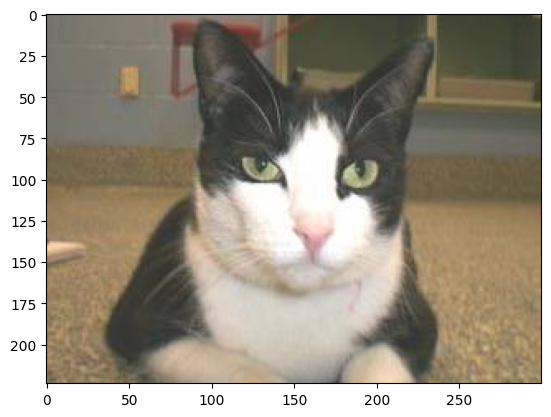

In [31]:
train_cat_fnames = os.listdir(train_cats_dir)
img_path = os.path.join(train_cats_dir, train_cat_fnames[0])
img = mpimg.imread(img_path)
plt.imshow(img)

In [32]:
type(img), img.shape, img[0,0,:], img.max()  # 8-bits

(numpy.ndarray,
 (224, 300, 3),
 array([116, 116, 106], dtype=uint8),
 np.uint8(255))

# 간단한 CNN을 사용한 모델


In [33]:
import tensorflow as tf
import tensorflow.keras as keras
from tensorflow.keras import layers
from tensorflow.keras import models
from tensorflow.keras import optimizers
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

"""
keras에서는 이미지데이터 학습을 쉽게하도록 하기위해 다양한 패키지를 제공한다. 그 중 하나가 ImageDataGenerator 클래스이다. ImageDataGenerator 클래스를 통해 객체를 생성할 때 파라미터를 전달해주는 것을 통해 데이터의 전처리를 쉽게할 수 있고, 또 이 객체의
flow_from_directory 메소드를 활용하면 폴더 형태로된 데이터 구조를 바로 가져와서 사용할 수 있다. 이 과정은 매우 직관적이고 코드도 ImageDataGenerator를 사용하지 않는 방법에 비해 상당히 짧아진다.

출처: https://3months.tistory.com/199 [Deep Play]
"""

#### ImageDataGenerator() object
- Generate batches of tensor image data with real-time data augmentation. The data
  will be looped over (in batches).
- flow_from_dataframe() method: Takes the dataframe and the path to a directory and
    generates batches of augmented/normalized data.
- flow_from_directory() method: Takes the path to a directory & generates batches of
    augmented data.

In [34]:
train_dir, validation_dir

('./cats_and_dogs_filtered/train', './cats_and_dogs_filtered/validation')

In [35]:
img_width = 150
img_height = 150

datagen = ImageDataGenerator(rescale = 1./255)
train_generator = datagen.flow_from_directory(directory=train_dir,
											   target_size=(img_width,img_height),
											   classes=['dogs','cats'],
											   class_mode='binary',
											   batch_size=20)

validation_generator = datagen.flow_from_directory(directory=validation_dir,
											   target_size=(img_width,img_height),
											   classes=['dogs','cats'],
											   class_mode='binary',
											   batch_size=20)

model = models.Sequential()
model.add(layers.Input(shape=(img_width, img_height, 3)))  # (150,150,3)
model.add(layers.Conv2D(32,(3,3), activation = 'relu'))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Conv2D(64,(3,3), activation = 'relu'))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Conv2D(128,(3,3), activation = 'relu'))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Conv2D(128,(3,3), activation = 'relu'))
model.add(layers.MaxPooling2D((2,2)))

model.add(layers.Flatten())
model.add(layers.Dense(512, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))

model.summary()

Found 3607 images belonging to 2 classes.
Found 1908 images belonging to 2 classes.


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

In [36]:
(3*3*3*32) + 32, 6272*512 + 512

(896, 3211776)

In [37]:
# for exercise (just for checking) - it will loop forever, so you need break !
# let's try to get 3 batches
i=0
for data_batch, labels_batch in train_generator:
    print(data_batch.shape, labels_batch.shape)
    i+=1
    if i==3: break

(20, 150, 150, 3) (20,)
(20, 150, 150, 3) (20,)
(20, 150, 150, 3) (20,)


- .fit은 전체 학습 데이터 세트가 메모리에 맞고 data augmentation 을 사용하지 않을 경우.
- .fit_generator는 메모리에 맞출 거대한 데이터 세트가 있거나 data augmentation 을 사용할 경우. -> .fit() 으로 통일됨.
  - The first argument is the **iterator** for the train images that we get from the flow() or flow_from_dataframe() or flow_from_directory() method.

In [38]:
model.compile(loss='binary_crossentropy',
              optimizer=optimizers.Adam(learning_rate=1e-4),
              metrics=['acc'])

history = model.fit(
    x=train_generator,
    steps_per_epoch=100,
    epochs=10,
    validation_data=validation_generator,
    validation_steps=50)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 32s 188ms/step - acc: 0.5083 - loss: 0.6949 - val_acc: 0.5060 - val_loss: 0.6895
Epoch 2/10
 81/100 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - acc: 0.5596 - loss: 0.6803

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 62ms/step - acc: 0.5889 - loss: 0.6724 - val_acc: 0.6150 - val_loss: 0.6532
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 66ms/step - acc: 0.6286 - loss: 0.6453 - val_acc: 0.5740 - val_loss: 0.6714
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 67ms/step - acc: 0.6556 - loss: 0.6242 - val_acc: 0.6510 - val_loss: 0.6291
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step - acc: 0.6810 - loss: 0.5916 - val_acc: 0.6800 - val_loss: 0.5780
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 100ms/step - acc: 0.7007 - loss: 0.5821 - val_acc: 0.6910 - val_loss: 0.5689
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 77ms/step - acc: 0.7292 - loss: 0.5466 - val_acc: 0.7180 - val_loss: 0.5614
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - acc: 0.7377 - loss: 0.5316 - val_acc: 0.6810 - val_loss: 0.5846
Epoch 9/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 80ms/step - acc: 0.7438 - loss: 0.5175 - val_acc: 0.7210 - val_loss: 0.5324
Epoch 10/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - a

- there are two types for saving the models
  - tensorflow SavedModel (recommended)(default for model.save())
  - keras H5 (파일명을 '.h5' 로 주거나 parameter format='h5')

In [39]:
# model 저장 방식 (현재는 아래 방식 권장)
# model.save('./sample_data/cats_and_dogs_from_lab60.h5')  # will be used later in this code
# or tf.keras.models.save_model()
# model = keras.models.load_model('./sample_data/cats_and_dogs_from_lab60.h5')

In [40]:
model.save('cats_and_dogs_from_lab60.keras')  # 최신 권장 방식 (확장자에 따라 결정됨)
model = keras.models.load_model('cats_and_dogs_from_lab60.keras')

In [41]:
# from google.colab import drive
# drive.mount('/content/drive')

## 성능 확인

Text(0.5, 1.0, 'Training(--) and validation loss')

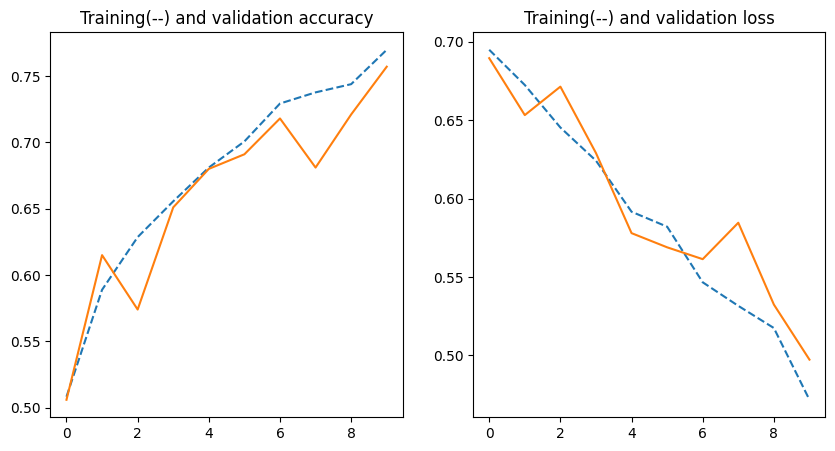

In [42]:
acc = history.history['acc']
val_acc = history.history['val_acc']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(acc))

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(epochs, acc, '--')
plt.plot(epochs, val_acc)
plt.title('Training(--) and validation accuracy')

plt.subplot(1,2,2)
plt.plot(epochs, loss,  '--')
plt.plot(epochs, val_loss)
plt.title('Training(--) and validation loss')


- 과대적합이 발생한 것을 알 수 있다.
  - 모델은 복잡한데 적은 수의 데이터를 반복 (이포크) 사용하여 훈련시킨 때문으로 보임.



# 데이터 증강 및 Dropout
- 드롭 아웃 계층은 훈련 시간 동안 각 단계의 rate 를 사용하여 입력 단위를 무작위로 0으로 설정하여 ovefitting 을 방지.
- 0 으로 설정되지 않은 입력은 모든 입력에 대한 합계가 변경되지 않도록 1 / (1-rate)만큼 scaled up.
- training 할 때만 적용되고 inference 할 때에는 drop 되지 않음.

In [43]:
img_width = 150
img_height = 150

In [44]:
train_datagen = ImageDataGenerator(
  rescale= 1./255,
  rotation_range = 40,
  width_shift_range = 0.2,
  height_shift_range = 0.2,
  shear_range=0.2,
  zoom_range=0.2,
  horizontal_flip = True)

validation_datagen = ImageDataGenerator(rescale = 1./255)

train_generator = train_datagen.flow_from_directory(directory=train_dir,
											   target_size=(img_width,img_height),
# 											   classes=['dogs','cats'],
											   class_mode='binary',
											   batch_size=20)

validation_generator = validation_datagen.flow_from_directory(directory=validation_dir,
											   target_size=(img_width,img_height),
# 											   classes=['dogs','cats'],
											   class_mode='binary',
											   batch_size=20)


model = models.Sequential()

model.add(layers.Input(shape=(img_width, img_height, 3)))
model.add(layers.Conv2D(32,(3,3), activation = 'relu'))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Conv2D(64,(3,3), activation = 'relu'))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Conv2D(128,(3,3), activation = 'relu'))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Conv2D(128,(3,3), activation = 'relu'))
model.add(layers.MaxPooling2D((2,2)))

model.add(layers.Flatten())
model.add(layers.Dropout(0.5))
model.add(layers.Dense(512, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))

Found 3607 images belonging to 2 classes.
Found 1908 images belonging to 2 classes.


In [45]:
model.compile(loss='binary_crossentropy',
              optimizer=optimizers.RMSprop(learning_rate=1e-4),
              metrics=['acc'])

history = model.fit(
    x=train_generator,
    steps_per_epoch=100,
    epochs=30,
    validation_data=validation_generator,
    validation_steps=50)

Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 27s 222ms/step - acc: 0.4997 - loss: 0.6964 - val_acc: 0.5060 - val_loss: 0.6895
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 16s 159ms/step - acc: 0.5272 - loss: 0.6916 - val_acc: 0.4930 - val_loss: 0.6888
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 20s 197ms/step - acc: 0.5340 - loss: 0.6907 - val_acc: 0.5680 - val_loss: 0.6831
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 20s 205ms/step - acc: 0.5358 - loss: 0.6840 - val_acc: 0.6060 - val_loss: 0.6694
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 21s 204ms/step - acc: 0.5715 - loss: 0.6803 - val_acc: 0.5810 - val_loss: 0.6740
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 16s 160ms/step - acc: 0.5737 - loss: 0.6777 - val_acc: 0.5940 - val_loss: 0.6637
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 20s 195ms/step - acc: 0.5883 - loss: 0.6719 - val_acc: 0.5910 - val_loss: 0.6579
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 16s 160ms/step - acc: 0.5827 - loss: 0.6687 - val_acc: 0.5470 - val_loss: 0.6822
Epoch 9/30
100/100 ━━━━━━━━━━━━━

Text(0.5, 1.0, 'Training(--) and validation loss')

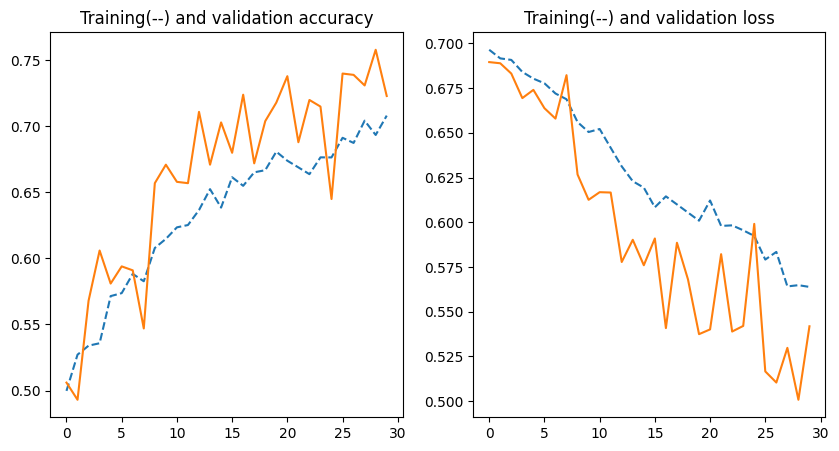

In [46]:
acc = history.history['acc']
val_acc = history.history['val_acc']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(acc))

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(epochs, acc, '--')
plt.plot(epochs, val_acc)
plt.title('Training(--) and validation accuracy')

plt.subplot(1,2,2)
plt.plot(epochs, loss,  '--')
plt.plot(epochs, val_loss)
plt.title('Training(--) and validation loss')

- 데이터 증식과 드롭아웃 덕택에 더이상 과대적합되지 않음을 볼 수 있다.

In [47]:
model.save('cats_and_dogs_from_lab60_augmented.keras')

In [48]:
model = keras.models.load_model('cats_and_dogs_from_lab60_augmented.keras')

# (Just to see how ImageDataGenerator works)

In [49]:
## just for reference to see output of the generators
img_iter = train_generator

for i in range(3):
    z = next(img_iter)

len(z), z[0].shape, z[1].shape   # input image (z[0]) and label (z[1])
                                 # batch_size = 20

(2, (20, 150, 150, 3), (20,))

In [50]:
z[1]

array([1., 1., 1., 0., 0., 1., 0., 0., 0., 0., 1., 0., 0., 1., 1., 0., 0.,
       0., 1., 1.], dtype=float32)

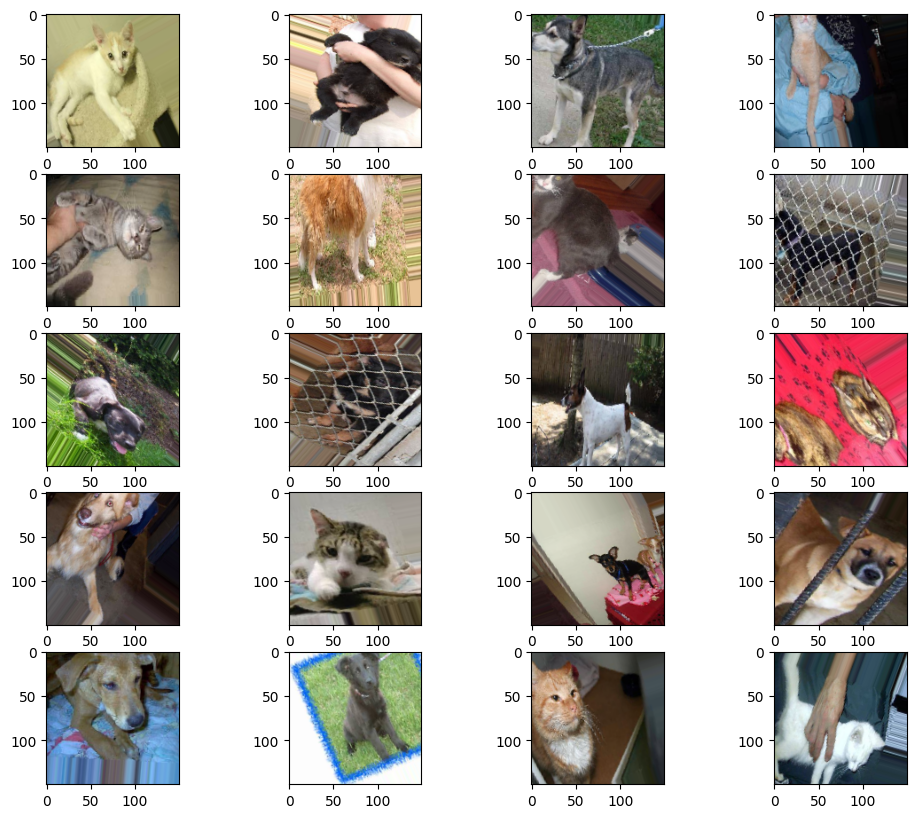

[0. 1. 1. 0. 0. 1. 0. 1. 1. 1. 1. 0. 1. 0. 1. 1. 1. 1. 0. 0.]


In [51]:
# to see augmented train images

z = next(train_generator)       # first batch

plt.figure(figsize=(12,10))

for i in range(20):
    plt.subplot(5,4,i+1)
    imgplot = plt.imshow(image.array_to_img(z[0][i]))
    i +=1
plt.show()
print(z[1])

In [59]:
model.predict(z[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


array([[0.25921708],
       [0.6398708 ],
       [0.71867603],
       [0.51675427],
       [0.5135355 ],
       [0.39162803],
       [0.4559053 ],
       [0.7465003 ],
       [0.482699  ],
       [0.16394556],
       [0.7588341 ],
       [0.2604319 ],
       [0.6356161 ],
       [0.746878  ],
       [0.32765776],
       [0.43496138],
       [0.56471574],
       [0.5046587 ],
       [0.79616547],
       [0.42156816]], dtype=float32)

In [60]:
(model.predict(z[0]) >= 0.5).astype(int).ravel()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


array([0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0])

In [61]:
((model.predict(z[0]) >= 0.5).astype(int).ravel() == z[1]).mean()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


np.float64(0.7)

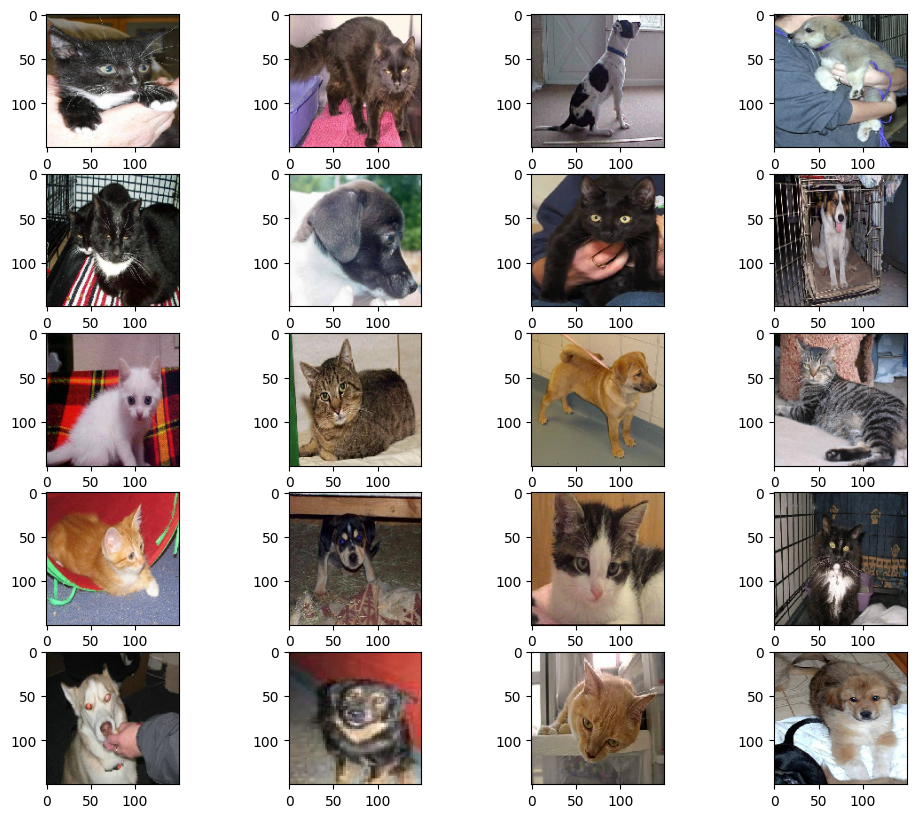

[0. 0. 1. 1. 0. 1. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0. 1. 1. 0. 1.]


In [53]:
# to see (unaugmented) validation images

z = next(validation_generator)  # first batch

plt.figure(figsize=(12,10))

for i in range(20):
    plt.subplot(5,4,i+1)
    imgplot = plt.imshow(image.array_to_img(z[0][i]))
    i +=1
plt.show()
print(z[1])

In [54]:
((model.predict(z[0]) >= 0.5).astype(int).ravel() == z[1]).mean()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 541ms/step


np.float64(0.7)

# (Random 데이터 증식된 훈련 이미지 보기)


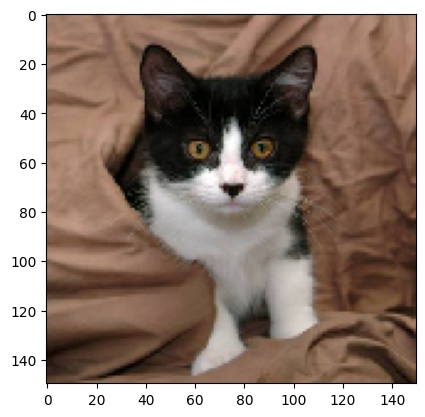

In [55]:
from keras.preprocessing import image   # 이미지 전처리 유틸리티 모듈

fnames = sorted([os.path.join(train_cats_dir, fname) for
                fname in os.listdir(train_cats_dir)])
img_path = fnames[3]  # 증식할 이미지 선택
img = image.load_img(img_path, target_size=(150,150)) # 이미지를 읽고 크기 변경

plt.imshow(img)

In [56]:
train_datagen = ImageDataGenerator(
    rescale= 1./255,
    rotation_range = 40,
    width_shift_range = 0.2,
    height_shift_range = 0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip = True)

In [57]:
# ImageDataGenerator.flow(): Takes data & label arrays, generates batches of augmented data.
# 배치 데이터를 기대하기 떄문에 샘플 데이터에 배치 차원을 추가하여 4-d 텐서로 만듬.

x = image.img_to_array(img)
x = x.reshape((1,) + x.shape)    # (1,150,150,3) 크기로 변환
print(x.shape)

(1, 150, 150, 3)


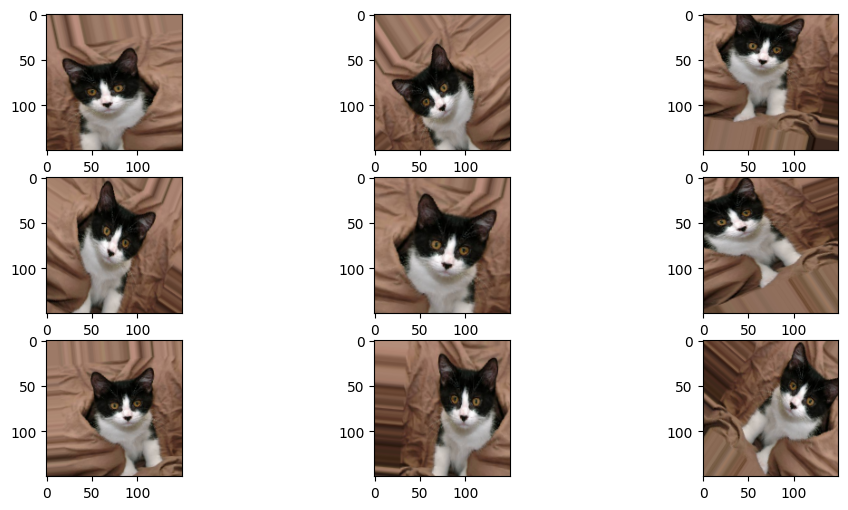

In [58]:
i = 0
plt.figure(figsize=(12,6))
for batch in train_datagen.flow(x, batch_size=1):   # endless loop (need break)
    plt.subplot(3,3,i+1)
    imgplot = plt.imshow(image.array_to_img(batch[0]))
    i +=1
    if i % 9 == 0:
        break
plt.show()

----------------------

# Exercise

In [ ]:
a = np.array([[1,2],[3,4]])
print(a.shape)
print(a.reshape(4,1))
print((1,) + a.shape)
(1,4) + (2,3)   # tuple concatenation

(2, 2)
[[1]
 [2]
 [3]
 [4]]
(1, 2, 2)


(1, 4, 2, 3)

## Augmnenting MNIST data

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.12/dist-packages/keras/src/legacy/preprocessing/image.py:622: UserWarning: NumpyArrayIterator is set to use the data format convention "channels_last" (channels on axis 3), i.e. expected either 1, 3, or 4 channels on axis 3. However, it was passed an array with shape (60000, 1, 28, 28) (28 channels).
  warnings.warn(


(9, 1, 28, 28)


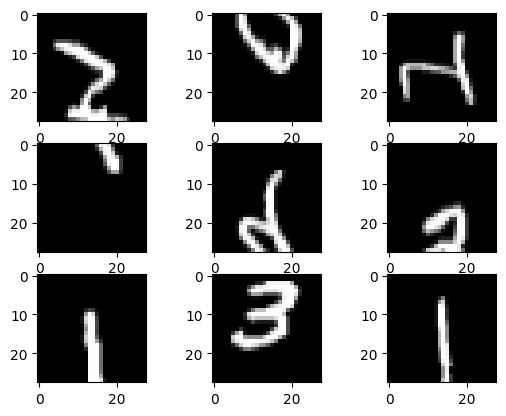

[5 0 4 1 9 2 1 3 1]


In [ ]:
from keras.datasets import mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train = X_train.reshape(X_train.shape[0],1,28,28).astype('float32')
datagen = ImageDataGenerator(
  rescale= 1./255,
  rotation_range = 40,
  width_shift_range = 0.2,
  height_shift_range = 0.2,
  shear_range=0.2,
  zoom_range=0.2,
  horizontal_flip = True)

# datagen.fit(X_train)
batch_size=9

# for X_batch, y_batch in datagen.flow(X_train, y_train, batch_size=batch_size, seed=42): # seed for shuffling and random transformation
for X_batch, y_batch in datagen.flow(X_train, y_train, batch_size=batch_size, shuffle=False) :
    print(X_batch.shape)
    for i in range(batch_size):
        plt.subplot(330 + 1 + i)
        plt.imshow(X_batch[i].reshape(28,28), cmap=plt.get_cmap('gray'))
    plt.show()
    print(y_batch)
    break